Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                     │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_13 (Dense)                     │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_14 (Dense)                     │ (None, 25)                  │           1,625 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 110,361 (431.10 KB)

 Trainable params: 110,361 (431.10 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/11
687/687 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - accuracy: 0.3086 - loss: 2.2754 - val_accuracy: 0.5158 - val_loss: 1.5900
Epoch 2/11
687/687 ━━━━━━━━━━━━━━━━━━━━ 16s 12ms/step - accuracy: 0.5686 - loss: 1.3606 - val_accuracy: 0.6461 - val_loss: 1.1274
Epoch 3/11
687/687 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.6774 - loss: 1.0001 - val_accuracy: 0.7347 - val_loss: 0.8417
Epoch 4/11
687/687 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.7606 - loss: 0.7586 - val_accuracy: 0.7842 - val_loss: 0.6691
Epoch 5/11
687/687 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.8176 - loss: 0.5909 - val_accuracy: 0.8079 - val_loss: 0.5639
Epoch 6/11
687/687 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.8568 - loss: 0.4694 - val_accuracy: 0.8408 - val_loss: 0.4748
Epoch 7/11
687/687 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.8858 - loss: 0.3743 - val_accuracy: 0.8590 - val_loss: 0.4070
Epoch 8/11
687/687 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.9104 - loss: 0.2965 - v

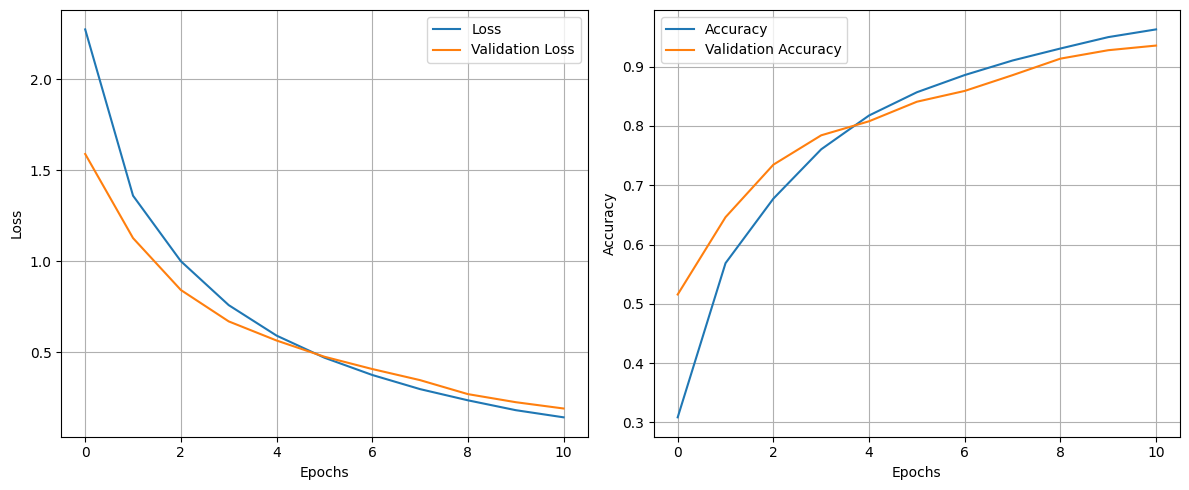

In [14]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

train_data = pd.read_csv('sign_mnist_train.csv')
test_data = pd.read_csv('sign_mnist_test.csv')

train_data.head()

x_train = train_data.drop('label', axis=1).values
y_train = train_data['label'].values

x_test = test_data.drop('label',axis=1).values
y_test = test_data['label'].values


x_train = x_train/255.0
x_test = x_test/255.0

model = keras.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(25, activation='softmax')
])

model.summary()
# optimizer = keras.optimizers.Adam(learning_rate=0.001),
model.compile(
    optimizer = keras.optimizers.SGD(learning_rate=0.01),
    loss = "sparse_categorical_crossentropy",
    metrics=['accuracy']
)

history = model.fit(x_train, y_train, batch_size=32, epochs=11,  validation_split=0.2)

loss, accuracy = model.evaluate(x_test, y_test)

print("Loss : ",loss)
print("Accuracy :", accuracy)

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history.history['loss'], label="Loss")
plt.plot(history.history['val_loss'], label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.grid(True)
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label="Accuracy")
plt.plot(history.history['val_accuracy'], label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

In [4]:
print("Traning data : ", train_data.shape)

Traning data :  (27455, 785)


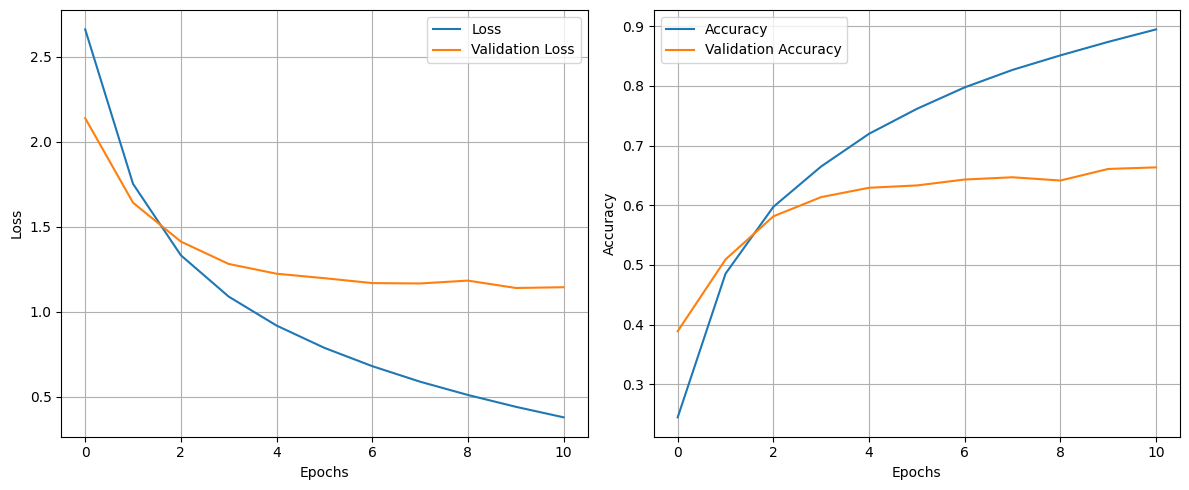